# Chapter 4 results, from summary data

This notebook recomputes the figures of Chapter 4 §4.6 and Table 4.6 from the summary
tables in [`data/`](data/), and draws the comparisons behind them.

**Read this first.**

- The CSVs in `data/` were **transcribed by hand** from the recorded screen output of the
  runs, not exported by the scripts. Their provenance is in [`data/README.md`](data/README.md).
  The checks below confirm that the figures in the chapter follow from these tables; they
  do not re-run the pipeline.
- Every length figure compares a clip with the length its identifier states. That tests
  consistency with scheduled durations, **not the position of a cut point**.
- "Sample" is every eleventh recording of the delivery (151 recordings). The October
  changes have been run on the sample only.

Run settings: [`docs/method.md`](../docs/method.md#settings-used-for-each-run).
Experiments: [`docs/experiments.md`](../docs/experiments.md).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
own = pd.read_csv(DATA / "own_length_by_group.csv")
chance = pd.read_csv(DATA / "chance_test.csv")
yield_rule = pd.read_csv(DATA / "yield_by_rule.csv")
align = pd.read_csv(DATA / "alignment_runs.csv")
refine = pd.read_csv(DATA / "refine_check_19.csv")
vstart = pd.read_csv(DATA / "video_start_by_year.csv")
cov = pd.read_csv(DATA / "coverage.csv").set_index("quantity")["value"]

def row(run, group):
    r = own[(own.run == run) & (own.group == group)]
    assert len(r) == 1, (run, group)
    return r.iloc[0]

# chart style: thin marks, recessive axes, text in ink colours
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3dd"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "text.color": INK,
})

## 1. Table 4.6, recomputed

Each line takes the figure from the summary tables and checks it against the value printed
in the chapter. A failed check stops the notebook.

In [2]:
v_all, v_notlast, v_last = row("v16", "all cut points"), row("v16", "not break-last"), row("v16", "break-last")
p_notlast, s3_notlast = row("s_prec", "not break-last"), row("s_v3", "not break-last")
obtained, total = cov["unique adverts obtained at least once (September run)"], cov["unique adverts in the first delivery"]
old, new = align.set_index("run").loc["s_own"], align.set_index("run").loc["s_own_rec2"]
r = refine.set_index("stage_b")

table = pd.DataFrame([
    ("Median difference from own stated length (s)", v_all.median_s, 0.042, "Full run, 24,872 clips"),
    ("Within 0.2 s, all clips (%)", round(v_all.pct_within_0_2s), 74, "Full run"),
    ("Within 0.2 s, last clips aside (%)", round(v_notlast.pct_within_0_2s), 83, "Full run"),
    ("Clips with a stated length", v_all.n, 24872, "Full run"),
    ("Unique adverts obtained (%)", round(100 * obtained / total, 1), 63.6, "Audit of 10 Oct"),
    ("Cut points kept, each break on its own", old.cut_points_kept, 2368, "Sample, Stage B off"),
    ("Cut points kept, alignment by recording", new.cut_points_kept, 2877, "Sample, Stage B off"),
    ("On the first frame, before (of 19)", r.loc["as in the September run", "exact"], 8, "19 frame-checked"),
    ("On the first frame, after (of 19)", r.loc["plus video start correction", "exact"], 16, "19 frame-checked"),
    ("Within 0.2 s, last clips aside, before (%)", p_notlast.pct_within_0_2s, 82.4, "Sample"),
    ("Within 0.2 s, last clips aside, after (%)", s3_notlast.pct_within_0_2s, 94.5, "Sample"),
    ("Last clips more than 5 s off (%)", round(v_last.pct_over_5s), 16, "Full run, 2,899 last clips"),
    ("Last clips", v_last.n, 2899, "Full run"),
], columns=["Figure", "From the data", "In Chapter 4", "Basis"])
table["Match"] = table["From the data"] == table["In Chapter 4"]
table[["From the data", "In Chapter 4"]] = table[["From the data", "In Chapter 4"]].map(lambda v: f"{v:g}")
assert table["Match"].all(), table[~table["Match"]]
table

,Figure,From the data,In Chapter 4,Basis,Match
0,Median difference from own stated length (s),0.042,0.042,"Full run, 24,872 clips",True
1,"Within 0.2 s, all clips (%)",74,74,Full run,True
2,"Within 0.2 s, last clips aside (%)",83,83,Full run,True
3,Clips with a stated length,24872,24872,Full run,True
4,Unique adverts obtained (%),63.6,63.6,Audit of 10 Oct,True
5,"Cut points kept, each break on its own",2368,2368,"Sample, Stage B off",True
6,"Cut points kept, alignment by recording",2877,2877,"Sample, Stage B off",True
7,"On the first frame, before (of 19)",8,8,19 frame-checked,True
8,"On the first frame, after (of 19)",16,16,19 frame-checked,True
9,"Within 0.2 s, last clips aside, before (%)",82.4,82.4,Sample,True


## 2. Where the clips fall short: place in the break and year

The September full run, each clip against its own stated length. The last clip of a break is
ended by a rule of its own, and it accounts for most of the gap between "all clips" and the
rest.

In [3]:
groups = ["all cut points", "within break", "break-first", "break-last", "not break-last",
          "break of 3-4 boundaries", "break of 5 or more"]
(own[(own.run == "v16") & own.group.isin(groups)]
    .set_index("group").loc[groups, ["n", "median_s", "pct_within_0_2s", "pct_over_1s", "pct_over_5s"]])

,n,median_s,pct_within_0_2s,pct_over_1s,pct_over_5s
group,,,,,
all cut points,24872,0.042,73.9,5.1,2.1
within break,22309,0.040,74.6,4.7,2.3
break-first,2563,0.079,67.9,8.1,0.1
break-last,2899,0.403,5.5,23.7,16.0
not break-last,21973,0.031,83.0,2.6,0.3
break of 3-4 boundaries,549,0.282,42.8,23.7,16.6
break of 5 or more,24323,0.040,74.6,4.7,1.8


## 3. The 2025–2026 gap was a timing mismatch

In the September run, clips from 2025 and 2026 fell well below earlier years. The cause was
in the files: their video stream starts later than the audio, and the picture detector had
been looking at the wrong frames. Below, the same 151 recordings before the October changes
(`s_prec`) and with both of them (`s_v3`), clips of every place in the break.

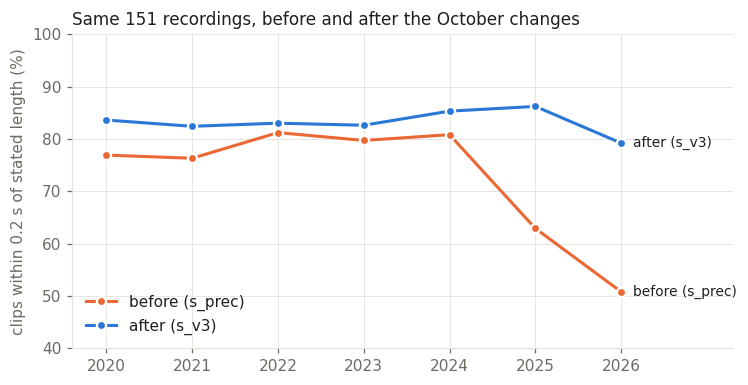

,year,files,video_start_over_0_1s,max_video_start_s,share_late
0,2020,158,0,0.00,0.0
1,2021,340,0,0.00,0.0
2,2022,207,0,0.00,0.0
3,2023,209,0,0.00,0.0
4,2024,294,0,0.00,0.0
5,2025,302,246,2.84,81.0
6,2026,160,160,2.68,100.0


In [4]:
years = [str(y) for y in range(2020, 2027)]
by_year = (own[own.group.isin(years)]
           .pivot(index="group", columns="run", values="pct_within_0_2s").loc[years])

fig, ax = plt.subplots(figsize=(7, 3.6))
x = [int(y) for y in years]
for run, colour, label in [("s_prec", ORANGE, "before (s_prec)"), ("s_v3", BLUE, "after (s_v3)")]:
    ax.plot(x, by_year[run], color=colour, linewidth=2, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.5, label=label)
    ax.annotate(label, (x[-1], by_year[run].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_ylim(40, 100)
ax.set_xlim(2019.6, 2027.3)
ax.set_xticks(x)
ax.set_ylabel("clips within 0.2 s of stated length (%)")
ax.set_title("Same 151 recordings, before and after the October changes",
             loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

vstart.assign(share_late=lambda d: (100 * d.video_start_over_0_1s / d.files).round(0))

## 4. Why the strict acceptance rule stays

Each break was fitted again five and seven minutes away from where it belongs, inside the
programme. A full match there is an accident. Looser rules keep slightly more breaks where
they belong and let in many more accidents.

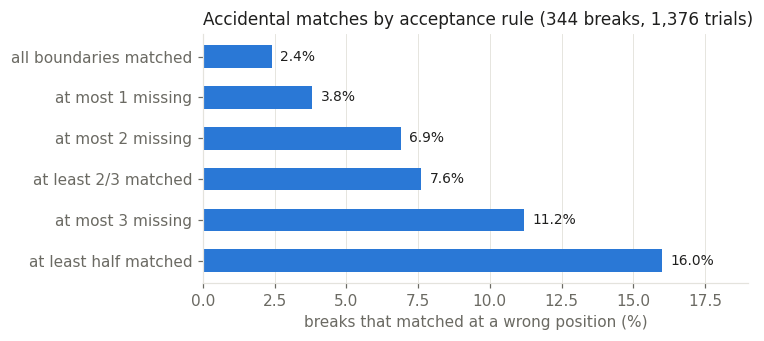

,rule,slots,filled,unique_adverts
0,all matched (strict),2913,0,2340
1,at most 1 filled,2949,5,2364
2,at most 2 filled,2988,17,2394
3,hit rate >= 0.8,2945,4,2360
4,hit rate >= 0.66,2995,18,2397
5,hit rate >= 0.5,3025,32,2418


In [5]:
c = chance[chance.break_size == "all"].set_index("rule")
order = ["all boundaries matched", "at most 1 missing", "at most 2 missing",
         "at least 2/3 matched", "at most 3 missing", "at least half matched"]
c = c.loc[order]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(c.index[::-1], c.pct_elsewhere[::-1], color=BLUE, height=0.55)
for i, v in enumerate(c.pct_elsewhere[::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("breaks that matched at a wrong position (%)")
ax.set_title("Accidental matches by acceptance rule (344 breaks, 1,376 trials)",
             loc="left", fontsize=11, color=INK)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 19)
plt.tight_layout()
plt.show()

yield_rule

Under the strict rule, the rate depends on the size of the break. Breaks of three or four
boundaries still match at a wrong position about one time in eight.

In [6]:
(chance[chance.rule == "all boundaries matched"]
    .set_index("break_size")[["breaks", "null_fits", "pass_elsewhere", "pct_elsewhere"]])

,breaks,null_fits,pass_elsewhere,pct_elsewhere
break_size,,,,
all,344,1376,33,2.4
3-4,35,140,17,12.1
5-7,86,344,8,2.3
8+,223,892,8,0.9


## 5. What these figures do not show

- **Position.** Every length figure above is about the distance between neighbouring cut
  points. A shift shared by every cut point passes unseen. Position rests on frame-by-frame
  checks, 23 so far; the 19 used for the October changes are summarised here:

In [7]:
refine

,stage_b,n,exact,within_2_frames,late_over_2,early_over_2,median_abs_error_frames,worst_frames
0,as in the September run,19,8,13,3,3,1.0,7
1,search the silence + 6-frame bound,19,14,16,0,3,0.3,7
2,plus video start correction,19,16,19,0,0,0.2,1


- **The whole delivery.** The October changes have been run on the sample only.
- **The last clip of a break.** No replacement rule has been tested.